<a href="https://colab.research.google.com/github/Koushikgmurthy/ML2/blob/main/program5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

             PLAY TENNIS DATASET
     Outlook Temperature Humidity  Windy Play
0      Sunny         Hot     High  False   No
1      Sunny         Hot     High   True   No
2   Overcast         Hot     High  False  Yes
3       Rain        Mild     High  False  Yes
4       Rain        Cool   Normal  False  Yes
5       Rain        Cool   Normal   True   No
6   Overcast        Cool   Normal   True  Yes
7      Sunny        Mild     High  False   No
8      Sunny        Cool   Normal  False  Yes
9       Rain        Mild   Normal  False  Yes
10     Sunny        Mild   Normal   True  Yes
11  Overcast        Mild     High   True  Yes
12  Overcast         Hot   Normal  False  Yes
13      Rain        Mild     High   True   No

Dataset Shape:
(14, 5)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14 entries, 0 to 13
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Outlook      14 non-null     object
 1   T

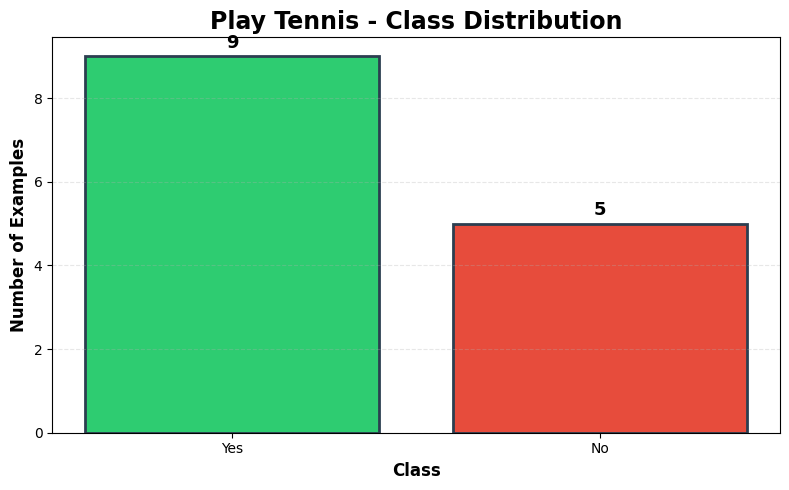



             RIPPER-STYLE RULES
Rule 1: IF Outlook = Sunny THEN Play = No (Accuracy = 60.00%)
Rule 2: IF Outlook = Overcast THEN Play = Yes (Accuracy = 100.00%)
Rule 3: IF Outlook = Rain THEN Play = Yes (Accuracy = 60.00%)
Rule 4: IF Temperature = Mild THEN Play = Yes (Accuracy = 66.67%)
Rule 5: IF Temperature = Cool THEN Play = Yes (Accuracy = 75.00%)
Rule 6: IF Humidity = Normal THEN Play = Yes (Accuracy = 85.71%)
Rule 7: IF Windy = False THEN Play = Yes (Accuracy = 75.00%)


             CN2-STYLE RULES
Rule 1: IF Outlook = Sunny THEN Play = No (Strength = 60.00%)
Rule 2: IF Outlook = Overcast THEN Play = Yes (Strength = 100.00%)
Rule 3: IF Outlook = Rain THEN Play = Yes (Strength = 60.00%)
Rule 4: IF Temperature = Mild THEN Play = Yes (Strength = 66.67%)
Rule 5: IF Temperature = Cool THEN Play = Yes (Strength = 75.00%)
Rule 6: IF Humidity = Normal THEN Play = Yes (Strength = 85.71%)
Rule 7: IF Windy = False THEN Play = Yes (Strength = 75.00%)


                 FOIL ALGORITHM

FO

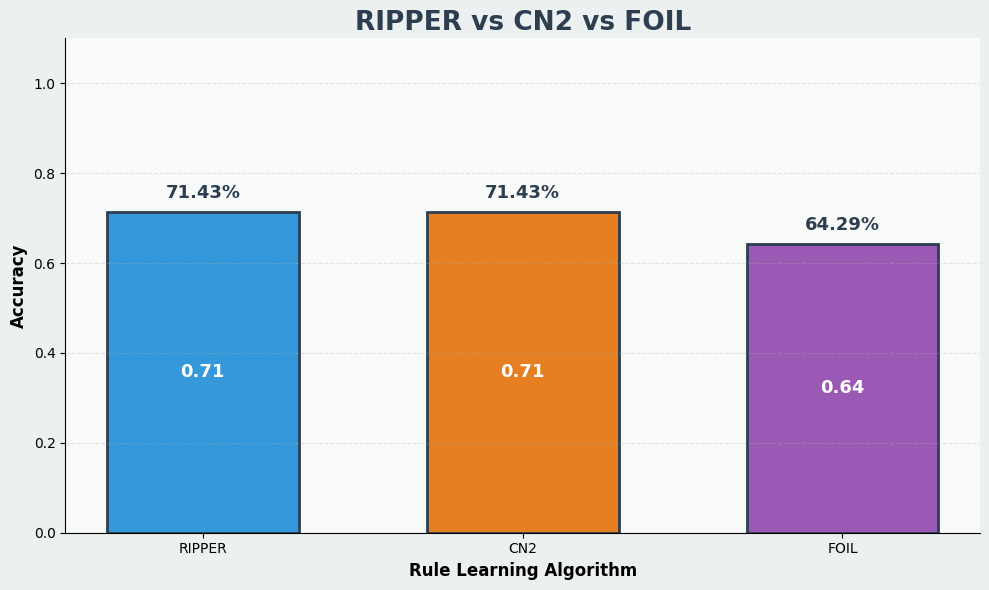

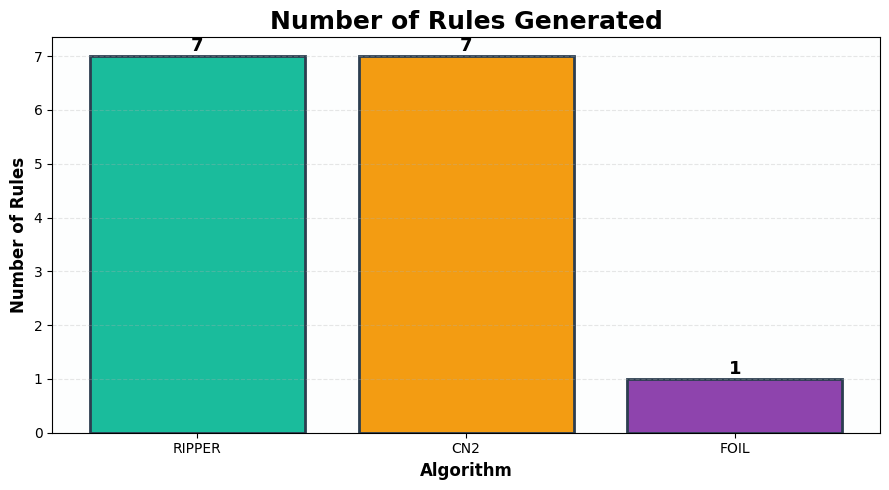



                    FINAL SUMMARY
RIPPER Accuracy : 71.43%
CN2 Accuracy    : 71.43%
FOIL Accuracy   : 64.29%

RIPPER Rules Generated : 7
CN2 Rules Generated    : 7
FOIL Rules Generated   : 1

Program completed successfully!


In [2]:
# ============================================================
# CLASSIFICATION RULE LEARNING
# RIPPER / CN2 / FOIL
# ============================================================

# Import libraries
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# 1. CREATE DATASET
# ============================================================

data = pd.DataFrame({

    "Outlook": [
        "Sunny", "Sunny", "Overcast", "Rain",
        "Rain", "Rain", "Overcast", "Sunny",
        "Sunny", "Rain", "Sunny", "Overcast",
        "Overcast", "Rain"
    ],

    "Temperature": [
        "Hot", "Hot", "Hot", "Mild",
        "Cool", "Cool", "Cool", "Mild",
        "Cool", "Mild", "Mild", "Mild",
        "Hot", "Mild"
    ],

    "Humidity": [
        "High", "High", "High", "High",
        "Normal", "Normal", "Normal", "High",
        "Normal", "Normal", "Normal", "High",
        "Normal", "High"
    ],

    "Windy": [
        "False", "True", "False", "False",
        "False", "True", "True", "False",
        "False", "False", "True", "True",
        "False", "True"
    ],

    "Play": [
        "No", "No", "Yes", "Yes",
        "Yes", "No", "Yes", "No",
        "Yes", "Yes", "Yes", "Yes",
        "Yes", "No"
    ]
})


# ============================================================
# 2. DISPLAY DATASET
# ============================================================

print("=" * 65)
print("             PLAY TENNIS DATASET")
print("=" * 65)

print(data)

print("\nDataset Shape:")
print(data.shape)

print("\nDataset Information:")
print(data.info())

print("\nClass Distribution:")
print(data["Play"].value_counts())


# ============================================================
# 3. CLASS DISTRIBUTION GRAPH
# ============================================================

class_counts = data["Play"].value_counts()

plt.figure(figsize=(8, 5))

bars = plt.bar(
    class_counts.index,
    class_counts.values,
    color=["#2ECC71", "#E74C3C"],
    edgecolor="#2C3E50",
    linewidth=2
)

plt.title(
    "Play Tennis - Class Distribution",
    fontsize=17,
    fontweight="bold"
)

plt.xlabel(
    "Class",
    fontsize=12,
    fontweight="bold"
)

plt.ylabel(
    "Number of Examples",
    fontsize=12,
    fontweight="bold"
)

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

for bar, value in zip(bars, class_counts.values):

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.2,
        str(value),
        ha="center",
        fontsize=13,
        fontweight="bold"
    )

plt.tight_layout()
plt.show()


# ============================================================
# 4. FEATURES
# ============================================================

features = [
    "Outlook",
    "Temperature",
    "Humidity",
    "Windy"
]

target = "Play"


# ============================================================
# 5. RIPPER-STYLE RULE GENERATION
# ============================================================

print("\n")
print("=" * 65)
print("             RIPPER-STYLE RULES")
print("=" * 65)


def generate_ripper_rules(df):

    rules = []

    for feature in features:

        values = df[feature].unique()

        for value in values:

            subset = df[
                df[feature] == value
            ]

            yes_count = len(
                subset[
                    subset["Play"] == "Yes"
                ]
            )

            no_count = len(
                subset[
                    subset["Play"] == "No"
                ]
            )

            total = yes_count + no_count

            if total == 0:
                continue

            # Select the majority class
            if yes_count > no_count:

                prediction = "Yes"

                accuracy = yes_count / total

            else:

                prediction = "No"

                accuracy = no_count / total

            # Keep useful rules
            if accuracy >= 0.60:

                rules.append({
                    "feature": feature,
                    "value": value,
                    "prediction": prediction,
                    "accuracy": accuracy,
                    "coverage": total
                })

    return rules


ripper_rules = generate_ripper_rules(data)


for i, rule in enumerate(
    ripper_rules,
    start=1
):

    print(
        f"Rule {i}: "
        f"IF {rule['feature']} = {rule['value']} "
        f"THEN Play = {rule['prediction']} "
        f"(Accuracy = {rule['accuracy']:.2%})"
    )


# ============================================================
# 6. CN2-STYLE RULE GENERATION
# ============================================================

print("\n")
print("=" * 65)
print("             CN2-STYLE RULES")
print("=" * 65)


def generate_cn2_rules(df):

    rules = []

    for feature in features:

        for value in df[feature].unique():

            subset = df[
                df[feature] == value
            ]

            yes_count = len(
                subset[
                    subset["Play"] == "Yes"
                ]
            )

            no_count = len(
                subset[
                    subset["Play"] == "No"
                ]
            )

            total = yes_count + no_count

            if total == 0:
                continue

            if yes_count >= no_count:

                prediction = "Yes"

                strength = yes_count / total

            else:

                prediction = "No"

                strength = no_count / total

            # CN2-style quality threshold
            if strength >= 0.60:

                rules.append({
                    "feature": feature,
                    "value": value,
                    "prediction": prediction,
                    "strength": strength,
                    "coverage": total
                })

    return rules


cn2_rules = generate_cn2_rules(data)


for i, rule in enumerate(
    cn2_rules,
    start=1
):

    print(
        f"Rule {i}: "
        f"IF {rule['feature']} = {rule['value']} "
        f"THEN Play = {rule['prediction']} "
        f"(Strength = {rule['strength']:.2%})"
    )


# ============================================================
# 7. FOIL ALGORITHM
# ============================================================

print("\n")
print("=" * 65)
print("                 FOIL ALGORITHM")
print("=" * 65)


import math


def foil_gain(
    positive_before,
    negative_before,
    positive_after,
    negative_after
):

    if positive_after == 0:
        return 0

    before_total = (
        positive_before +
        negative_before
    )

    after_total = (
        positive_after +
        negative_after
    )

    if before_total == 0 or after_total == 0:
        return 0

    before_probability = (
        positive_before /
        before_total
    )

    after_probability = (
        positive_after /
        after_total
    )

    if before_probability == 0:
        return 0

    gain = positive_after * (
        math.log2(after_probability)
        -
        math.log2(before_probability)
    )

    return gain


# Positive and negative examples

positive_examples = data[
    data["Play"] == "Yes"
]

negative_examples = data[
    data["Play"] == "No"
]


best_foil_rule = None
best_gain = -999


print("\nFOIL Gain Values:")
print("-" * 65)


for feature in features:

    for value in data[feature].unique():

        positive_after = len(
            positive_examples[
                positive_examples[feature] == value
            ]
        )

        negative_after = len(
            negative_examples[
                negative_examples[feature] == value
            ]
        )

        gain = foil_gain(
            len(positive_examples),
            len(negative_examples),
            positive_after,
            negative_after
        )

        print(
            f"{feature} = {value:<10} "
            f"Gain = {gain:.3f}"
        )

        if gain > best_gain:

            best_gain = gain

            best_foil_rule = {
                "feature": feature,
                "value": value,
                "prediction": "Yes",
                "gain": gain
            }


# Display best rule

print("\n")
print("BEST FOIL RULE")
print("-" * 65)

print(
    f"IF {best_foil_rule['feature']} = "
    f"{best_foil_rule['value']} "
    f"THEN Play = Yes"
)

print(
    f"FOIL Gain = "
    f"{best_foil_rule['gain']:.3f}"
)


# ============================================================
# 8. PREDICTION FUNCTION
# ============================================================

def predict_rule(row, rules):

    for rule in rules:

        if (
            row[rule["feature"]]
            ==
            rule["value"]
        ):

            return rule["prediction"]

    # Default class
    return "No"


# ============================================================
# 9. RIPPER PREDICTIONS
# ============================================================

ripper_predictions = []

for _, row in data.iterrows():

    prediction = predict_rule(
        row,
        ripper_rules
    )

    ripper_predictions.append(
        prediction
    )


# ============================================================
# 10. CN2 PREDICTIONS
# ============================================================

cn2_predictions = []

for _, row in data.iterrows():

    prediction = predict_rule(
        row,
        cn2_rules
    )

    cn2_predictions.append(
        prediction
    )


# ============================================================
# 11. FOIL PREDICTIONS
# ============================================================

foil_predictions = []

for _, row in data.iterrows():

    if (
        row[best_foil_rule["feature"]]
        ==
        best_foil_rule["value"]
    ):

        prediction = "Yes"

    else:

        prediction = "No"

    foil_predictions.append(
        prediction
    )


# ============================================================
# 12. ADD PREDICTIONS TO DATASET
# ============================================================

data["RIPPER"] = ripper_predictions

data["CN2"] = cn2_predictions

data["FOIL"] = foil_predictions


print("\n")
print("=" * 65)
print("                 PREDICTIONS")
print("=" * 65)

print(data)


# ============================================================
# 13. CALCULATE ACCURACY
# ============================================================

ripper_accuracy = (
    data["RIPPER"] ==
    data["Play"]
).mean()


cn2_accuracy = (
    data["CN2"] ==
    data["Play"]
).mean()


foil_accuracy = (
    data["FOIL"] ==
    data["Play"]
).mean()


# ============================================================
# 14. PERFORMANCE TABLE
# ============================================================

results = pd.DataFrame({

    "Algorithm": [
        "RIPPER",
        "CN2",
        "FOIL"
    ],

    "Accuracy": [
        ripper_accuracy,
        cn2_accuracy,
        foil_accuracy
    ]
})


print("\n")
print("=" * 65)
print("                 MODEL PERFORMANCE")
print("=" * 65)

print(results.to_string(index=False))


# ============================================================
# 15. COLORFUL ACCURACY GRAPH
# ============================================================

plt.figure(
    figsize=(10, 6)
)


colors = [
    "#3498DB",
    "#E67E22",
    "#9B59B6"
]


bars = plt.bar(
    results["Algorithm"],
    results["Accuracy"],
    color=colors,
    edgecolor="#2C3E50",
    linewidth=2,
    width=0.6
)


plt.title(
    "RIPPER vs CN2 vs FOIL",
    fontsize=19,
    fontweight="bold",
    color="#2C3E50"
)

plt.xlabel(
    "Rule Learning Algorithm",
    fontsize=12,
    fontweight="bold"
)

plt.ylabel(
    "Accuracy",
    fontsize=12,
    fontweight="bold"
)

plt.ylim(
    0,
    1.1
)


plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)


# Accuracy above bars

for bar, value in zip(
    bars,
    results["Accuracy"]
):

    plt.text(
        bar.get_x()
        +
        bar.get_width() / 2,

        value + 0.03,

        f"{value:.2%}",

        ha="center",

        fontsize=13,

        fontweight="bold",

        color="#2C3E50"
    )


# Value inside bars

for bar, value in zip(
    bars,
    results["Accuracy"]
):

    plt.text(
        bar.get_x()
        +
        bar.get_width() / 2,

        value / 2,

        f"{value:.2f}",

        ha="center",

        va="center",

        color="white",

        fontsize=13,

        fontweight="bold"
    )


plt.gca().set_facecolor(
    "#F8F9F9"
)

plt.gcf().patch.set_facecolor(
    "#ECF0F1"
)


plt.gca().spines[
    "top"
].set_visible(False)

plt.gca().spines[
    "right"
].set_visible(False)


plt.tight_layout()

plt.show()


# ============================================================
# 16. RULE COUNT GRAPH
# ============================================================

rule_counts = [
    len(ripper_rules),
    len(cn2_rules),
    1
]


plt.figure(
    figsize=(9, 5)
)


bars = plt.bar(
    ["RIPPER", "CN2", "FOIL"],
    rule_counts,
    color=[
        "#1ABC9C",
        "#F39C12",
        "#8E44AD"
    ],
    edgecolor="#2C3E50",
    linewidth=2
)


plt.title(
    "Number of Rules Generated",
    fontsize=18,
    fontweight="bold"
)

plt.xlabel(
    "Algorithm",
    fontsize=12,
    fontweight="bold"
)

plt.ylabel(
    "Number of Rules",
    fontsize=12,
    fontweight="bold"
)


plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)


for bar, value in zip(
    bars,
    rule_counts
):

    plt.text(
        bar.get_x()
        +
        bar.get_width() / 2,

        value + 0.1,

        str(value),

        ha="center",

        fontsize=13,

        fontweight="bold"
    )


plt.gca().set_facecolor(
    "#FDFEFE"
)

plt.tight_layout()

plt.show()


# ============================================================
# 17. FINAL SUMMARY
# ============================================================

print("\n")
print("=" * 65)
print("                    FINAL SUMMARY")
print("=" * 65)

print(
    f"RIPPER Accuracy : "
    f"{ripper_accuracy:.2%}"
)

print(
    f"CN2 Accuracy    : "
    f"{cn2_accuracy:.2%}"
)

print(
    f"FOIL Accuracy   : "
    f"{foil_accuracy:.2%}"
)

print(
    f"\nRIPPER Rules Generated : "
    f"{len(ripper_rules)}"
)

print(
    f"CN2 Rules Generated    : "
    f"{len(cn2_rules)}"
)

print(
    f"FOIL Rules Generated   : 1"
)

print("\nProgram completed successfully!")
